In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy import stats
import utils
import seaborn as sns
import pingouin as pg
import matplotlib.cm as cm

import statsmodels.api as sm
from statsmodels.stats.anova import AnovaRM
from pathlib import Path

from natsort import index_natsorted

path_figs = "./Figs/"
Path(path_figs).mkdir(parents=True, exist_ok=True)

fingers = ['1', '2', '3', '4', '5']
index_finger = utils.index_finger

iti = utils.iti
planTime = utils.planTime
feedbackTime = utils.feedbackTime

total_sub_num = utils.total_sub_num
conditions = utils.conditions

# Fill in after collection, or leave None to keep every subject in subjs.csv
sub_nums = None

utils.set_figure_style("1col")
sns.color_palette('colorblind')


[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [31]:
# reload utils
import importlib
importlib.reload(utils)


<module 'utils' from '/Users/amin/projects/LearningDynamics/ChordAdaptationDynamics/SingleFingerGainGeneralization/utils.py'>

Load trial-level data written by `DatPreProcessing.ipynb` from `Single_Finger_Gain_Generalization_miscs/subjs.csv`.


In [33]:
subjs_path = utils.path_misc + 'subjs.csv'
if not Path(subjs_path).exists():
    raise FileNotFoundError(
        f"{subjs_path} not found. Run DatPreProcessing.ipynb after .dat files are copied in."
    )

subjs = pd.read_csv(subjs_path, sep='\t')

if sub_nums is not None:
    subjs = subjs[subjs['subNum'].isin(sub_nums)].reset_index(drop=True)

subjs


,subNum,BN,TN,TotalTrialNum,trial_num_within_condition,targetForce1,targetForce2,targetForce3,targetForce4,targetForce5,...,trialErrorType,num_targets,chord,condition,prev_condition,prev_perturbation,prev_trialCorr,transition,day,count
0,1,1,1,1,1,0.0,1.5,0.0,0.0,0.0,...,0,1,-^---,1.5,NaN,NaN,NaN,NaN,1,1
1,1,1,2,2,1,0.0,-3.0,0.0,0.0,0.0,...,0,1,-v---,-3.0,1.5,0.81,1.0,1.5->-3.0,1,1
2,1,1,3,3,2,0.0,-3.0,0.0,0.0,0.0,...,0,1,-v---,-3.0,-3.0,-0.31,1.0,-3.0->-3.0,1,1
3,1,1,4,4,1,0.0,3.0,0.0,0.0,0.0,...,0,1,-^---,3.0,-3.0,-0.26,1.0,-3.0->3.0,1,1
4,1,1,5,5,1,0.0,-1.5,0.0,0.0,0.0,...,0,1,-v---,-1.5,3.0,-0.54,1.0,3.0->-1.5,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1276,3,10,28,316,90,0.0,3.0,0.0,0.0,0.0,...,2,1,-^---,3.0,1.5,-0.08,1.0,1.5->3.0,1,1
1277,3,10,29,317,73,0.0,-3.0,0.0,0.0,0.0,...,1,1,-v---,-3.0,3.0,-1.14,0.0,3.0->-3.0,1,1
1278,3,10,30,318,91,0.0,3.0,0.0,0.0,0.0,...,0,1,-^---,3.0,-3.0,0.14,0.0,-3.0->3.0,1,1
1279,3,10,31,319,92,0.0,3.0,0.0,0.0,0.0,...,0,1,-^---,3.0,3.0,-0.90,1.0,3.0->3.0,1,1


In [35]:
subjs.T

,0,1,2,3,4,5,6,7,8,9,...,1271,1272,1273,1274,1275,1276,1277,1278,1279,1280
subNum,1,1,1,1,1,1,1,1,1,1,...,3,3,3,3,3,3,3,3,3,3
BN,1,1,1,1,1,1,1,1,1,1,...,10,10,10,10,10,10,10,10,10,10
TN,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,27,28,29,30,31,32
TotalTrialNum,1,2,3,4,5,6,7,8,9,10,...,311,312,313,314,315,316,317,318,319,320
trial_num_within_condition,1,1,2,1,1,2,3,4,3,4,...,74,78,72,79,80,90,73,91,92,75
targetForce1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
targetForce2,1.5,-3.0,-3.0,3.0,-1.5,-1.5,-3.0,-3.0,-1.5,-1.5,...,-1.5,1.5,-3.0,1.5,1.5,3.0,-3.0,3.0,3.0,-1.5
targetForce3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
targetForce4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
targetForce5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [36]:
subjs_correct = utils.remove_error_trials(subjs).copy()

subjs_grouped = subjs_correct.groupby(['subNum', 'condition']).agg({
    'count': 'sum',
}).reset_index()

subjs_grouped


,subNum,condition,count
0,1,-3.0,75
1,1,-1.5,77
2,1,1.5,85
3,1,3.0,75
4,2,-3.0,150
5,2,-1.5,152
6,2,1.5,148
7,2,3.0,149
8,3,-3.0,72
9,3,-1.5,74


### Error rates


In [37]:
subjs_err = subjs.groupby(['subNum', 'trialCorr']).size().reset_index(name='num_trials')
subjs_err.sort_values(by=['subNum', 'trialCorr'])


,subNum,trialCorr,num_trials
0,1,0,8
1,1,1,312
2,2,0,42
3,2,1,599
4,3,0,8
5,3,1,312


### Produced force over trials (index finger), by target extent


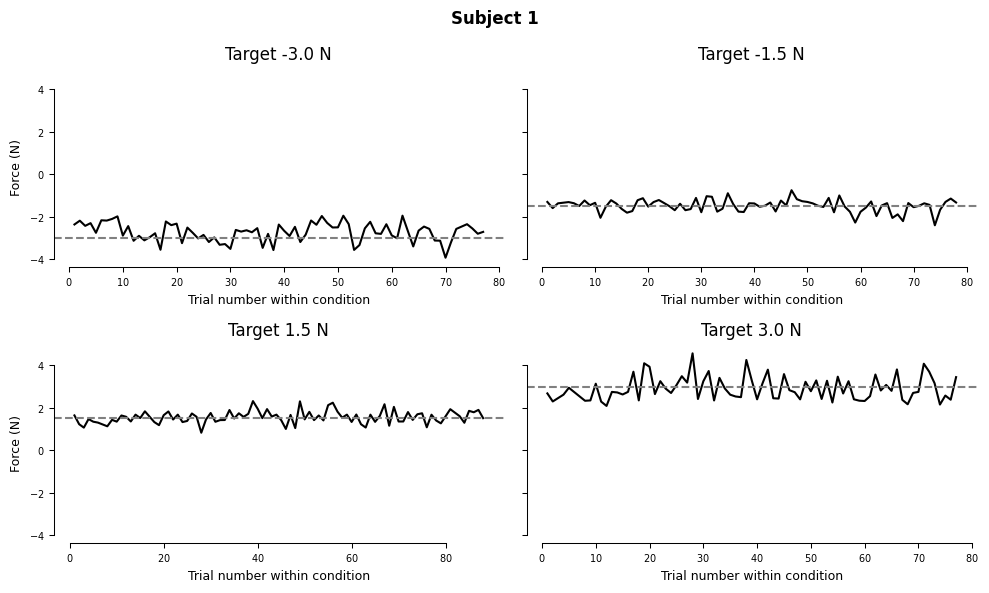

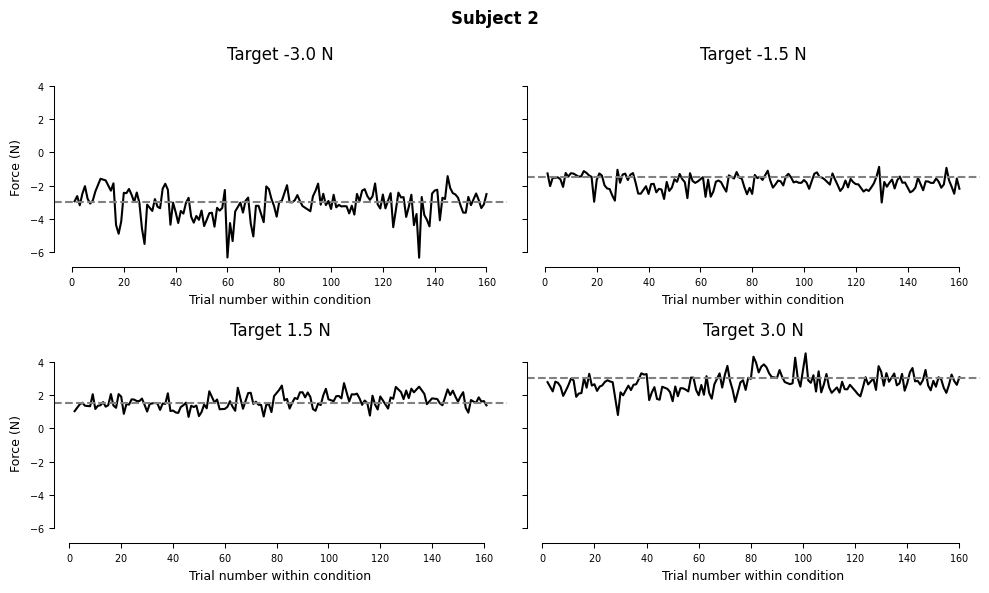

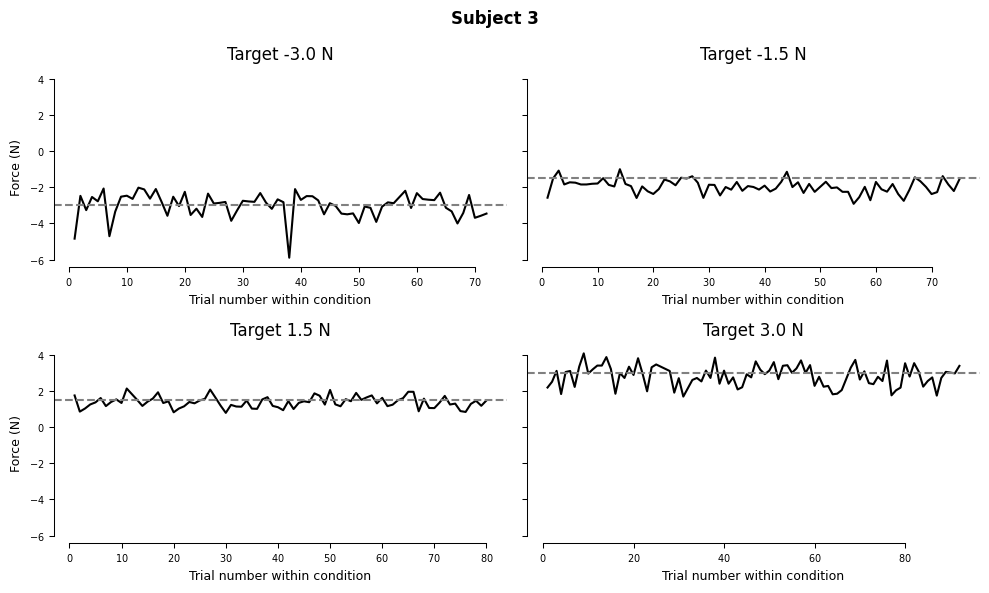

In [38]:
for subnum, subj_data in subjs_correct.groupby('subNum'):
    fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
    axs = axs.ravel()
    for ax, cond in zip(axs, conditions):
        cond_data = subj_data[subj_data['condition'] == cond]
        sns.lineplot(
            data=cond_data,
            x='trial_num_within_condition',
            y=f'endForce{index_finger}',
            ax=ax,
            color='black',
            errorbar=None,
        )
        ax.axhline(cond, color='gray', linestyle='--')
        ax.set_xlabel('Trial number within condition')
        ax.set_ylabel('Force (N)')
        ax.set_title(f'Target {cond} N')
    sns.despine(trim=True)
    fig.suptitle(f'Subject {subnum}')
    plt.tight_layout()
    plt.show()


## Learning rates by transition

There are **16 transitions** (each of the 4 target extents to each of the 4). Method A is estimated **separately for each transition, within each participant**:

$$B = -\mathrm{cov}(X_{t+1},\, p_t)\,/\,\mathrm{var}(p_t)$$

`X` is the produced index force (`endForce`), not a target deviation. `p_t` is the perturbation on the previous trial.

An error trial is unusable for lag-1 learning: it has no sampled force, and its perturbation did not happen, so the **next** trial cannot use that `p_t` either. Pairs are kept only when **both** trial `t` and trial `t+1` are correct (`trials_for_learning_rate`).


# Method A — 16 transitions per participant


In [39]:
# X_{t+1} = produced force (endForce). Do not subtract the target:
# B = -cov(X_{t+1}, p_t) / var(p_t) is already mean-centered, and the
# design plot is the slope of regressing p_t onto produced X_{t+1}.

subjs_learn = utils.trials_for_learning_rate(subjs)
print(
    f"learning-rate trials: {len(subjs_learn)} / {len(subjs)} "
    f"(dropped errors + trials after an error + first trial of each subject)"
)

pairs = utils.learning_pairs(subjs)
B_by_trans = utils.learning_rates_by_transition(subjs)

print("pairs per transition (subject × from × to):")
print(
    pairs.groupby(['subNum', 'from', 'to']).size()
    .unstack('to')
    .reindex(index=pd.MultiIndex.from_product(
        [sorted(subjs['subNum'].unique()), conditions], names=['subNum', 'from']
    ), columns=conditions)
)
B_by_trans


learning-rate trials: 1166 / 1281 (dropped errors + trials after an error + first trial of each subject)
pairs per transition (subject × from × to):
to           -3.0  -1.5   1.5   3.0
subNum from                        
1      -3.0    19    19    19    15
       -1.5    15    20    21    18
        1.5    22    18    21    22
        3.0    17    20    20    17
2      -3.0    37    36    34    34
       -1.5    33    37    34    37
        1.5    35    32    36    35
        3.0    34    34    34    37
3      -3.0    11    20    15    23
       -1.5    17    16    18    20
        1.5    20    16    22    20
        3.0    22    21    22    21


,subNum,from,to,n_pairs,B
0,1,-3.0,-3.0,19,0.433107
1,1,-3.0,-1.5,19,0.181799
2,1,-3.0,1.5,19,-0.218240
3,1,-3.0,3.0,15,-1.078890
4,1,-1.5,-3.0,15,0.184948
5,1,-1.5,-1.5,20,0.400921
6,1,-1.5,1.5,21,-0.290345
7,1,-1.5,3.0,18,-0.068111
8,1,1.5,-3.0,22,-0.261956
9,1,1.5,-1.5,18,-0.248708


### Transition learning rates vs next-trial extent

Same layout as the design-prediction figure: \(B\) against \(T_{t+1}\), one series per previous target \(T_t\). Gain adaptation predicts lines through the origin with slope \(\propto 1/T_t\); an additive offset predicts a flat line.


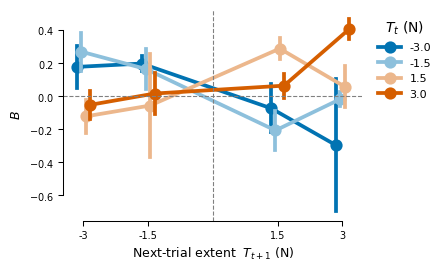

In [40]:
from matplotlib.colors import to_rgb

def with_opacity(color, alpha, background=(1, 1, 1)):
    """Simulate alpha by blending toward the background (seaborn ignores RGBA alpha)."""
    c = np.asarray(to_rgb(color))
    bg = np.asarray(background)
    return tuple(alpha * c + (1 - alpha) * bg)

cb = sns.color_palette('colorblind')
# Negative → colorblind[0]; positive → colorblind[3]. Larger |target| → higher opacity.
palette = {
    -3.0: with_opacity(cb[0], 1.0),
    -1.5: with_opacity(cb[0], 0.45),
     1.5: with_opacity(cb[3], 0.45),
     3.0: with_opacity(cb[3], 1.0),
}

utils.set_figure_style('1.5col')
fig, ax = plt.subplots()
sns.pointplot(
    data=B_by_trans,
    x='to',
    y='B',
    hue='from',
    order=conditions,
    hue_order=conditions,
    palette=palette,
    errorbar='se',
    dodge=0.2,
    native_scale=True,
    ax=ax,
)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xticks(conditions)
ax.set_xticklabels([f'{c:g}' for c in conditions])
ax.set_xlabel(r'Next-trial extent  $T_{t+1}$ (N)')
ax.set_ylabel(r'$B$')
ax.legend(title=r'$T_t$ (N)', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine(trim=True)
plt.tight_layout()
plt.savefig(path_figs + 'transition_learning_rates.pdf', bbox_inches='tight')
plt.savefig(path_figs + 'transition_learning_rates.png', dpi=300, bbox_inches='tight')
plt.show()
